In [1]:
!pip -q install gensim POT

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gensim.downloader as api
from gensim.parsing.preprocessing import STOPWORDS
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [3]:
glove = api.load("glove-wiki-gigaword-50")
print("GloVe loaded.")

[==================================================] 100.0% 66.0/66.0MB downloaded
GloVe loaded.


In [4]:
s1 = "Obama speaks to the media in Illinois"
s2 = "The president greets the press in Chicago"
s3 = "Oranges are my favorite fruit"
s4 = "The team won the football match yesterday"
sents = [s1, s2, s3, s4]

def prep(s):
    return [w for w in s.lower().split() if w not in STOPWORDS and w in glove]

for s in sents: print(prep(s))

['obama', 'speaks', 'media', 'illinois']
['president', 'greets', 'press', 'chicago']
['oranges', 'favorite', 'fruit']
['team', 'won', 'football', 'match', 'yesterday']


In [5]:
print("WMD(s1, s2) =", round(glove.wmdistance(prep(s1), prep(s2)), 4), " <- similar meaning")
print("WMD(s1, s3) =", round(glove.wmdistance(prep(s1), prep(s3)), 4), " <- unrelated")
print("WMD(s1, s4) =", round(glove.wmdistance(prep(s1), prep(s4)), 4))

WMD(s1, s2) = 0.8515  <- similar meaning
WMD(s1, s3) = 1.2269  <- unrelated
WMD(s1, s4) = 1.1221


,S1,S2,S3,S4
S1,0.000,0.852,1.227,1.122
S2,0.852,0.000,1.250,1.112
S3,1.227,1.250,0.000,1.180
S4,1.122,1.112,1.180,0.000


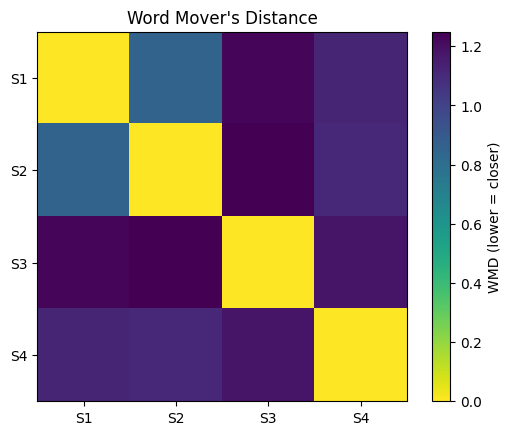

In [6]:
n = len(sents)
D = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        D[i, j] = glove.wmdistance(prep(sents[i]), prep(sents[j]))
labels = [f"S{i+1}" for i in range(n)]
display(pd.DataFrame(D, index=labels, columns=labels).round(3))

plt.imshow(D, cmap="viridis_r"); plt.colorbar(label="WMD (lower = closer)")
plt.xticks(range(n), labels); plt.yticks(range(n), labels); plt.title("Word Mover's Distance"); plt.show()

In [7]:
tf = TfidfVectorizer().fit_transform([s1, s2])
print("TF-IDF cosine(s1, s2) =", round(float(cosine_similarity(tf[0], tf[1])[0, 0]), 4), "(no shared words -> 0)")
print("WMD(s1, s2)           =", round(glove.wmdistance(prep(s1), prep(s2)), 4), "(captures semantic closeness)")

TF-IDF cosine(s1, s2) = 0.2424 (no shared words -> 0)
WMD(s1, s2)           = 0.8515 (captures semantic closeness)


In [8]:
query = "The prime minister talks to journalists in Delhi"
res = sorted((glove.wmdistance(prep(query), prep(s)), s) for s in sents)
for d, s in res: print(round(d, 3), "|", s)

1.05 | The president greets the press in Chicago
1.053 | Obama speaks to the media in Illinois
1.138 | The team won the football match yesterday
1.302 | Oranges are my favorite fruit
